# Task 1: Exploratory Data Analysis

**Author:** Yeap Jie Shen (22062548)
**Course:** WQF7009 Explainable Artificial Intelligence, Assignment 1

**Objective:** understand the Kaggle Stroke Prediction dataset (fedesoriano, 2021) before modelling: its target balance, data quality, risk factors and feature interactions. This prepares the reading of the SHAP explanations in Tasks 2–6.

**Approach:** extends the provided `scripts/00_data_exploration.py` (deepfindr, 2021) and loads data through its `DataLoader`.

**Contents**
0. [Provided script](#sec-provided)
1. [Load data](#sec-load)
2. [Summary statistics](#sec-summary)
3. [Target: class imbalance](#sec-target)
4. [Data quality](#sec-quality)
5. [Univariate distributions](#sec-univariate)
6. [Features vs stroke](#sec-bivariate)
7. [Feature interactions](#sec-interactions)
8. [Key takeaways](#sec-takeaways)
9. [References](#sec-references)

In [1]:
import os
import platform
import subprocess
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.stats import chi2_contingency, mannwhitneyu

from stroke_shap.data import axis_label, display_label
from stroke_shap.plotting import COLORS, FIGURE_WIDTH, label_panels, save_figure, set_theme

sys.path.append("../scripts")
from utils import DataLoader  # provided loader (deepfindr, 2021)

set_theme()

<a id="sec-provided"></a>
## 0. Provided script

**Method:** the provided `scripts/00_data_exploration.py` (deepfindr, 2021) is executed unchanged, as a separate process from `scripts/`. Plotting is non-interactive (`MPLBACKEND=Agg`) so its histograms do not block. The table records the command, exit code, the script's first output line and the environment.

**Fixes needed to run the provided code** (shared `scripts/utils.py`, commit `5d0aea6`):
- The data path is resolved from the repository root instead of the working directory.
- One-hot columns are encoded as 0/1 integers; pandas ≥ 2 returns booleans by default.

The rest of this notebook extends the script's steps (load, `info()`, histograms, preprocessing) with statistics and stroke-specific analysis.

In [2]:
run = subprocess.run(
    [sys.executable, "00_data_exploration.py"],
    cwd="../scripts",
    capture_output=True,
    text=True,
    env={**os.environ, "MPLBACKEND": "Agg"},
)
assert run.returncode == 0, run.stderr

packages = ["pandas", "numpy", "matplotlib", "scipy", "scikit-learn", "imbalanced-learn", "shap"]
pd.Series(
    {
        "command": "python 00_data_exploration.py",
        "exit code": run.returncode,
        "first output line (data shape)": run.stdout.splitlines()[0],
        "Python": platform.python_version(),
        "OS": platform.platform(),
        **{pkg: version(pkg) for pkg in packages},
    }
).to_frame("value")

,value
command,python 00_data_exploration.py
exit code,0
first output line (data shape),"(5110, 12)"
Python,3.14.10
OS,Windows-11-10.0.26300-SP0
pandas,2.3.3
numpy,2.5.4
matplotlib,3.11.2
scipy,1.18.1
scikit-learn,1.9.1


<a id="sec-load"></a>
## 1. Load data

The raw data: one row per patient. `info()` shows column types and non-null counts. Category labels are title-cased here for readability (e.g. `never smoked` → `Never Smoked`); the models use `DataLoader`'s raw values.

In [3]:
data_loader = DataLoader()
data_loader.load_dataset()
data = data_loader.data.copy()
text_cols = data.select_dtypes("object").columns
data[text_cols] = data[text_cols].apply(lambda s: s.str.replace("_", " ").str.title())
data

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,Formerly Smoked,1
1,51676,Female,61.0,0,0,Yes,Self-Employed,Rural,202.21,NaN,Never Smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,Never Smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,Smokes,1
4,1665,Female,79.0,1,0,Yes,Self-Employed,Rural,174.12,24.0,Never Smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,Never Smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-Employed,Urban,125.20,40.0,Never Smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-Employed,Rural,82.99,30.6,Never Smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,Formerly Smoked,0


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


<a id="sec-summary"></a>
## 2. Summary statistics

Continuous and categorical features are summarised separately; `id` is an identifier and is ignored. The second table lists each category's count and share and is referred to throughout.

In [5]:
continuous = ["age", "avg_glucose_level", "bmi"]
categorical = [
    "gender",
    "hypertension",
    "heart_disease",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]

data[continuous].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.2,22.6,0.1,25.0,45.0,61.0,82.0
avg_glucose_level,5110.0,106.1,45.3,55.1,77.2,91.9,114.1,271.7
bmi,4909.0,28.9,7.9,10.3,23.5,28.1,33.1,97.6


In [6]:
pd.concat(
    {
        col: data[col].value_counts().to_frame("n").assign(pct=lambda d: (100 * d.n / len(data)).round(1))
        for col in categorical
    },
    names=["feature", "value"],
)

n   pct
feature        value                      
gender         Female           2994  58.6
               Male             2115  41.4
               Other               1   0.0
hypertension   0                4612  90.3
               1                 498   9.7
heart_disease  0                4834  94.6
               1                 276   5.4
ever_married   Yes              3353  65.6
               No               1757  34.4
work_type      Private          2925  57.2
               Self-Employed     819  16.0
               Children          687  13.4
               Govt Job          657  12.9
               Never Worked       22   0.4
Residence_type Urban            2596  50.8
               Rural            2514  49.2
smoking_status Never Smoked     1892  37.0
               Unknown          1544  30.2
               Formerly Smoked   885  17.3
               Smokes            789  15.4

<a id="sec-target"></a>
## 3. Target: class imbalance

How often does stroke occur? When one class dominates, accuracy is misleading: a model that always predicts "no stroke" would be right for the whole majority share.

**Result:** about 20 patients without stroke for every stroke patient (4.9% positive).

**Implication:**
- The provided `DataLoader.oversample` duplicates training strokes up to a 50/50 balance (Task 2).
- Evaluation should focus on stroke recall rather than accuracy.

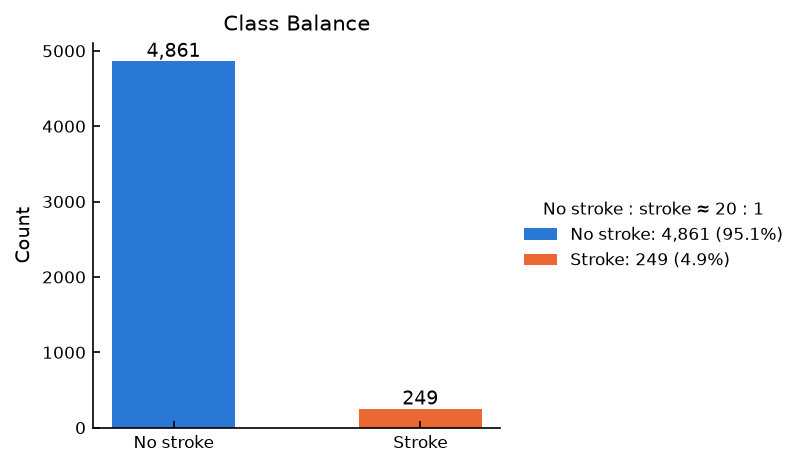

In [7]:
counts = data["stroke"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 3))
for outcome, name, color in [(0, "No stroke", COLORS["blue"]), (1, "Stroke", COLORS["orange"])]:
    bar = ax.bar(
        name,
        counts[outcome],
        color=color,
        width=0.5,
        label=f"{name}: {counts[outcome]:,} ({counts[outcome] / counts.sum():.1%})",
    )
    ax.bar_label(bar, fmt="{:,.0f}")
ax.set(ylabel="Count", title="Class Balance")
ax.legend(
    title=f"No stroke : stroke ≈ {counts[0] / counts[1]:.0f} : 1",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)
save_figure(fig, "eda_class_balance")
plt.show()

<a id="sec-quality"></a>
## 4. Data quality

### 4.1 Missing values

Only `bmi` has missing values: 201 patients (3.9%, table below).

In [8]:
missing = data.isna().sum()
missing[missing > 0].to_frame("missing").assign(pct=lambda d: (100 * d.missing / len(data)).round(1))

,missing,pct
bmi,201,3.9


**Question:** is stroke more common among patients whose BMI is missing?

**Method:** compare the stroke share in the two groups, and test the association with a chi-square test of independence (Pearson, 1900).

**Result:**
- Strokes make up 19.9% of the missing-BMI group vs 4.3% of the recorded group, about 4.7 times the share.
- The association is significant (p < .001).

**Implication:**
- `DataLoader.preprocess_data` fills missing BMI with **0**, so the model can learn "BMI = 0 → stroke". That is an artefact of how the data was collected, not a clinical effect.
- This is checked in the SHAP dependence plot (Task 4).

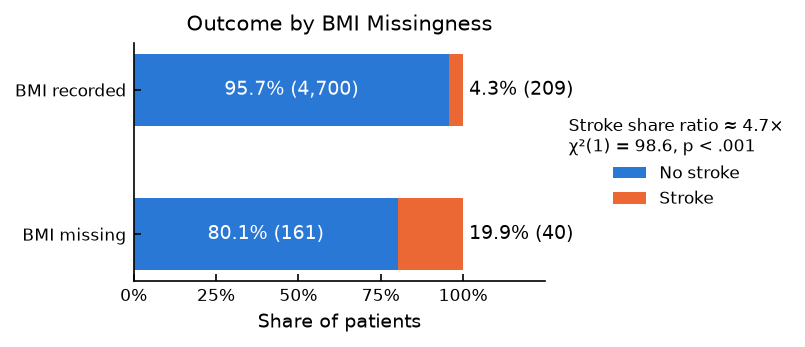

In [9]:
bmi_status = data["bmi"].isna().map({True: "BMI missing", False: "BMI recorded"})
table = pd.crosstab(bmi_status, data["stroke"])
share = table.div(table.sum(axis=1), axis=0)
chi2, p, dof, _ = chi2_contingency(table)
ratio = share.loc["BMI missing", 1] / share.loc["BMI recorded", 1]

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 2.2))
bars = ax.barh(share.index, share[0], color=COLORS["blue"], height=0.5, label="No stroke")
ax.bar_label(
    bars,
    labels=[f"{s:.1%} ({n:,})" for s, n in zip(share[0], table[0], strict=True)],
    label_type="center",
    color="white",
)
bars = ax.barh(share.index, share[1], left=share[0], color=COLORS["orange"], height=0.5, label="Stroke")
ax.bar_label(bars, labels=[f" {s:.1%} ({n:,})" for s, n in zip(share[1], table[1], strict=True)])
ax.set_xlim(0, 1.25)
ax.set_xticks(np.linspace(0, 1, 5))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Share of patients", title="Outcome by BMI Missingness")
p_text = "p < .001" if p < 0.001 else f"p = {p:.3f}"
ax.legend(
    title=f"Stroke share ratio ≈ {ratio:.1f}×\nχ²({dof}) = {chi2:.1f}, {p_text}",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)
save_figure(fig, "eda_bmi_missing")
plt.show()

<a id="sec-4-2"></a>

### 4.2 Rare and placeholder categories

From the value counts in [Section 2](#sec-summary), three categories need attention:
- `gender = Other` (1 patient) and `work_type = Never Worked` (22, no strokes): too rare to learn from. **Kept unchanged:** dropping rows would change the 80/20 split, so the baseline would no longer match the provided code. The single `Other` patient falls in the training set, so it is never explained.
- `smoking_status = Unknown`: 1,544 patients (30%).

**Hypothesis:** smoking history is often not collected for children, so `Unknown` patients should be younger than those with a recorded status.

**Method:** compare the age distributions with a two-sided Mann–Whitney U test (Mann & Whitney, 1947). This rank-based test suits age, which is not normally distributed.

**Result:**
- Supported: `Unknown` patients have a median age of 23 and 44% are under 18, vs 1–7% in the other groups.
- The difference is significant (p < .001, legend).

**Implication:** `Unknown` is not missing independently of age. It partly marks being young, which a model may exploit.

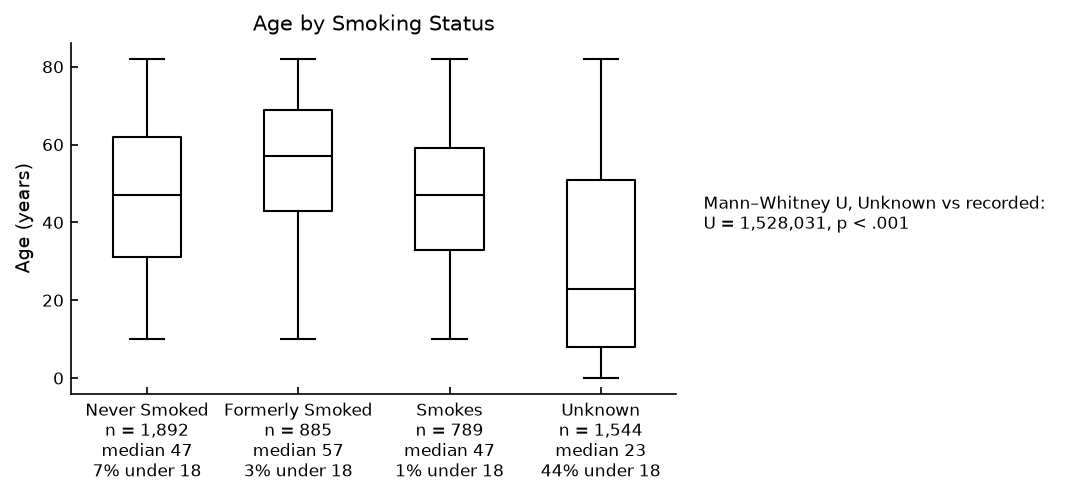

In [10]:
order = ["Never Smoked", "Formerly Smoked", "Smokes", "Unknown"]
groups = [data.loc[data["smoking_status"] == status, "age"] for status in order]

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 3.2))
ax.boxplot(
    groups,
    widths=0.45,
    tick_labels=[
        f"{s}\nn = {len(g):,}\nmedian {g.median():.0f}\n{(g < 18).mean():.0%} under 18"
        for s, g in zip(order, groups, strict=True)
    ],
)
u, p = mannwhitneyu(groups[-1], data.loc[data["smoking_status"] != "Unknown", "age"])
p_text = "p < .001" if p < 0.001 else f"p = {p:.3f}"
ax.legend(
    handles=[],
    title=f"Mann–Whitney U, Unknown vs recorded:\nU = {u:,.0f}, {p_text}",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)
ax.set(ylabel="Age (years)", title="Age by Smoking Status")
save_figure(fig, "eda_smoking_unknown_age")
plt.show()

<a id="sec-4-3"></a>

### 4.3 Duplicates

Each `id` should appear once, and no two patients should share every other value. Both counts are 0.

In [11]:
pd.Series(
    {
        "duplicate IDs": data.id.duplicated().sum(),
        "duplicate records (excluding id)": data.drop(columns="id").duplicated().sum(),
    }
).to_frame("count")

,count
duplicate IDs,0
duplicate records (excluding id),0


<a id="sec-4-4"></a>

### 4.4 Data-quality summary

The checks above collected in one table, in the order of the report template. Every number is shown in the referenced section's output.

| Check or statistic | Observed result | Action or interpretation | Ref. |
|---|---|---|---|
| Rows and columns | 5,110 rows; 12 columns | One row per patient; `id` is excluded from the predictors | [1](#sec-load) |
| Duplicate records or IDs | 0 duplicate IDs; 0 duplicate records (excluding `id`) | Nothing removed | [4.3](#sec-4-3) |
| Missing values by variable | `bmi`: 201 (3.9%); `smoking_status` Unknown: 1,544 (30.2%); all other columns: 0 | Missing BMI has a 4.7× higher stroke share; Unknown smoking is kept as its own category, not merged with Never Smoked | [4.1](#sec-quality), [4.2](#sec-4-2) |
| Stroke class counts | No stroke: 4,861; stroke: 249 (4.9%) | About 20 : 1 imbalance; evaluate with recall, precision and AUC rather than accuracy | [3](#sec-target) |
| Age (years) | Mean 43.2 ± 22.6; median 45.0 (IQR 25.0–61.0); range 0.1–82.0 | Plausible; 856 patients are under 18 | [2](#sec-summary), [6.2](#sec-6-2) |
| Average glucose level (mg/dL) | Mean 106.1 ± 45.3; median 91.9 (IQR 77.2–114.1); range 55.1–271.7 | Bimodal; the upper peak (above 169, IQR outliers) is consistent with diabetes and kept. Units are not stated in the source; mg/dL is assumed from the range | [2](#sec-summary), [5.1](#sec-univariate) |
| BMI (kg/m²) | Mean 28.9 ± 7.9; median 28.1 (IQR 23.5–33.1); range 10.3–97.6 | Values above 47.5 are IQR outliers but plausible; kept | [2](#sec-summary), [5.1](#sec-univariate) |
| Categorical distributions | `gender` Other: 1 (<0.1%); `work_type` Never Worked: 22 (0.4%); all other levels ≥ 5% | Rare levels kept unchanged, so the split matches the provided code; too few rows to learn from | [2](#sec-summary) |

<a id="sec-univariate"></a>
## 5. Univariate distributions

### 5.1 Continuous features

Histograms show each feature's shape. Boxplots flag outliers by Tukey's (1977) rule: values more than 1.5 × IQR beyond the quartiles (dashed fences; counts under each boxplot).

**Result:**
- **Age:** spread fairly evenly from 0 to 82, with no outliers.
- **Average glucose:**
  - Right-skewed and bimodal.
  - The values above the upper fence form a second peak around 200 mg/dL and above, the diagnostic threshold for diabetes on a random glucose test (American Diabetes Association, 2021).
  - They are a real subgroup, not errors.
- **BMI:**
  - Right-skewed.
  - The values above the fence reach 97.6 (maximum, [Section 2](#sec-summary)): extreme but physiologically possible.

**Implication for later tasks:**
- No rows are removed. The random forest (Tasks 2–4) splits on thresholds, so extreme values do not distort it.
- The neural network in Task 6 is sensitive to scale, so its inputs will be standardised.
- The glucose peak should appear as a step in the SHAP dependence plot for glucose.

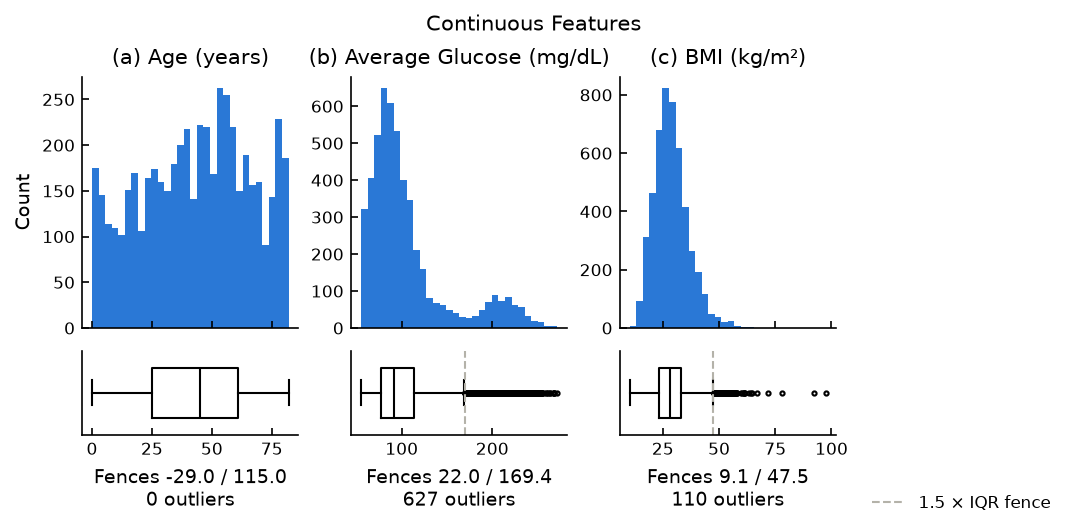

In [12]:
q1, q3 = data[continuous].quantile(0.25), data[continuous].quantile(0.75)
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

fig, axes = plt.subplots(2, 3, figsize=(FIGURE_WIDTH, 3.4), height_ratios=[3, 1], sharex="col")
for j, column in enumerate(continuous):
    values = data[column].dropna()
    n_outliers = ((values < lower[column]) | (values > upper[column])).sum()
    axes[0, j].hist(values, bins=30)
    axes[0, j].set_title(axis_label(column))
    axes[1, j].boxplot(values, orientation="horizontal", widths=0.6, flierprops={"markersize": 2})
    for fence in (lower[column], upper[column]):
        if values.min() <= fence <= values.max():
            axes[1, j].axvline(fence, color=COLORS["grey"], ls="--", lw=1)
    axes[1, j].set_yticks([])
    axes[1, j].set_xlabel(f"Fences {lower[column]:.1f} / {upper[column]:.1f}\n{n_outliers} outliers")
axes[0, 0].set_ylabel("Count")
label_panels(axes[0])
fig.legend(
    handles=[Line2D([], [], color=COLORS["grey"], ls="--", lw=1, label="1.5 × IQR fence")],
    loc="outside right lower",
)
fig.suptitle("Continuous Features")
save_figure(fig, "eda_continuous")
plt.show()

### 5.2 Categorical features

Bars are labelled with count and share.

**Result:**
- Hypertension (9.7%) and heart disease (5.4%) are uncommon.
- Gender and residence type are roughly balanced.
- `gender = Other` and `work_type = Never Worked` are tiny groups.

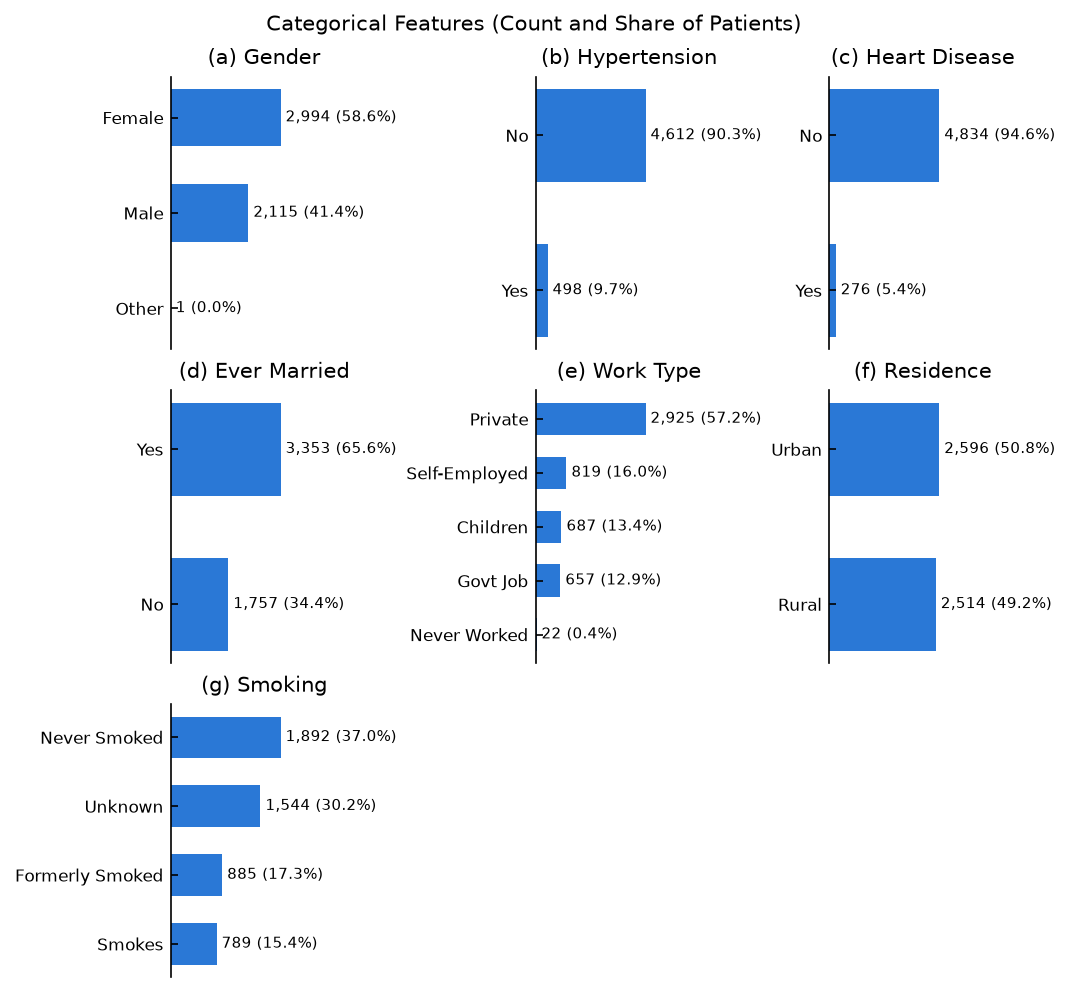

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(FIGURE_WIDTH, 6.5))
for ax, column in zip(axes.flat, categorical, strict=False):
    counts = data[column].replace({0: "No", 1: "Yes"}).value_counts(ascending=True)
    bars = ax.barh(counts.index.astype(str), counts.values, height=0.6)
    ax.bar_label(bars, labels=[f" {n:,} ({n / len(data):.1%})" for n in counts.values], fontsize=7)
    ax.set_xlim(0, counts.max() * 1.7)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(display_label(column))
label_panels(axes.flat[: len(categorical)])
for ax in axes.flat[len(categorical) :]:
    ax.axis("off")
fig.suptitle("Categorical Features (Count and Share of Patients)")
save_figure(fig, "eda_categorical")
plt.show()

<a id="sec-bivariate"></a>
## 6. Features vs stroke

<a id="sec-6-1"></a>

### 6.1 Continuous features by outcome

Each class is normalised separately (density), so the shapes are comparable despite the imbalance.

**Result:**
- Strokes are concentrated above about 50 years.
- A larger share of stroke patients than of non-stroke patients falls in the high-glucose peak.
- The BMI distributions overlap almost completely.

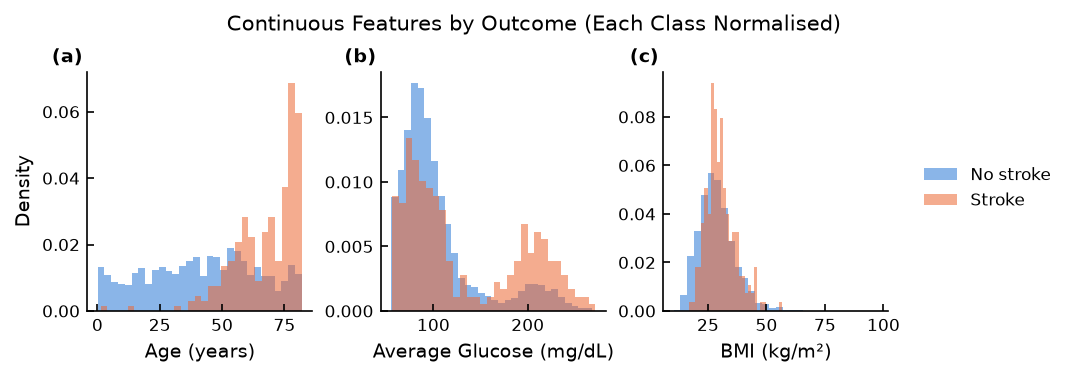

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, 2.4))
for ax, column in zip(axes, continuous, strict=True):
    for outcome, color, label in [(0, COLORS["blue"], "No stroke"), (1, COLORS["orange"], "Stroke")]:
        ax.hist(
            data.loc[data["stroke"] == outcome, column].dropna(),
            bins=30,
            density=True,
            alpha=0.55,
            color=color,
            label=label,
        )
    ax.set_xlabel(axis_label(column))
axes[0].set_ylabel("Density")
label_panels(axes)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle("Continuous Features by Outcome (Each Class Normalised)")
save_figure(fig, "eda_continuous_by_stroke")
plt.show()

<a id="sec-6-2"></a>

### 6.2 Categorical features: stroke rate per group

Bars are labelled with the stroke rate and strokes / patients. Age is binned and included for reference.

**Result:**
- **Age** has by far the steepest gradient: 0.2% under 18 vs 21.5% at 80+.
- **Hypertension** (13.3% vs 4.0%) and **heart disease** (17.0% vs 4.2%) are associated with a stroke rate about 3–4 times higher.
- **Ever married**, **self-employed** and **formerly smoked** groups also look riskier. [Section 7.2](#sec-confounding) checks whether that reflects age.
- **Gender** and **residence type** show little difference.

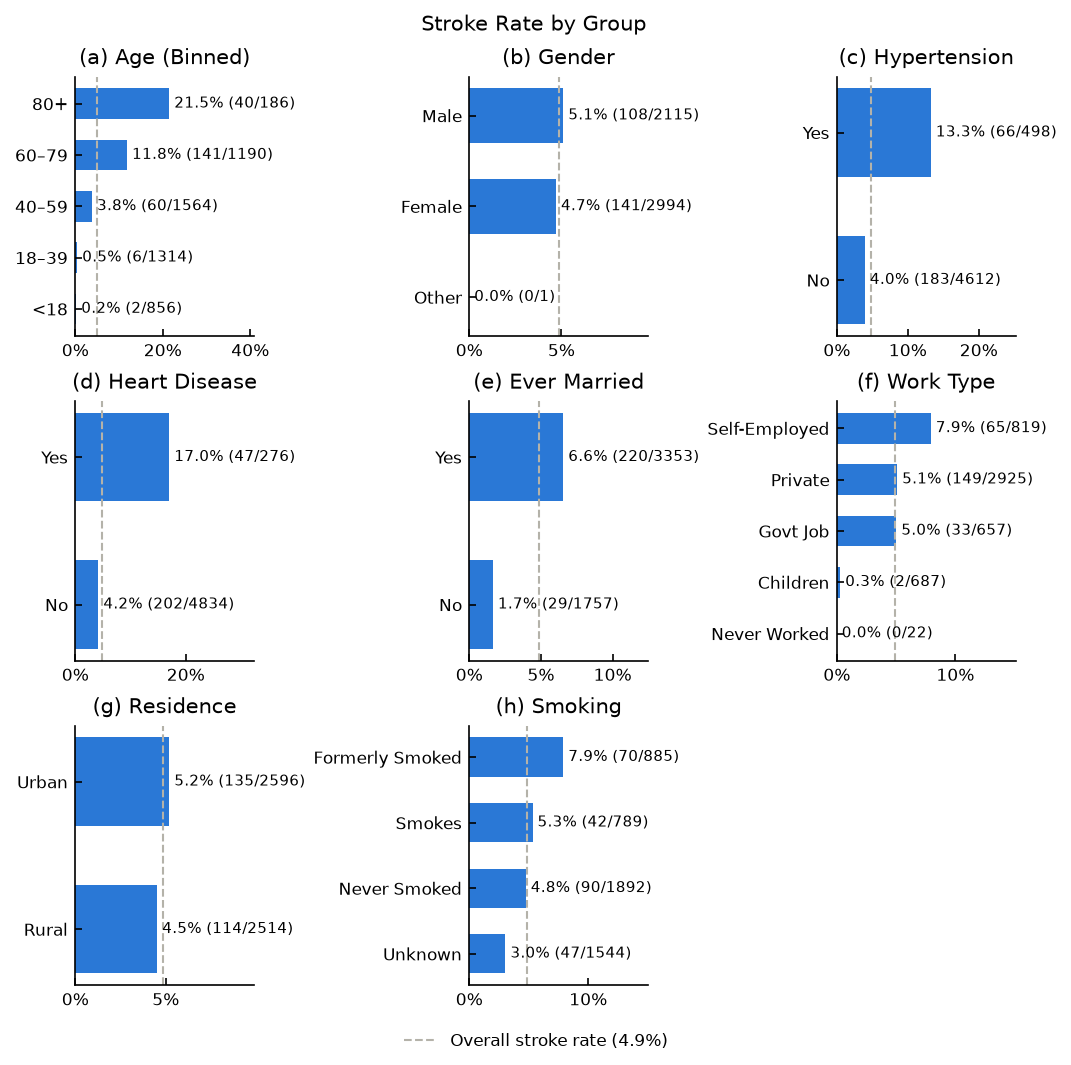

In [15]:
age_groups = pd.cut(
    data["age"], [0, 18, 40, 60, 80, np.inf], right=False, labels=["<18", "18–39", "40–59", "60–79", "80+"]
)
groups = {
    "Age (Binned)": age_groups,
    **{display_label(c): data[c].replace({0: "No", 1: "Yes"}) for c in categorical},
}
overall = data["stroke"].mean()

fig, axes = plt.subplots(3, 3, figsize=(FIGURE_WIDTH, 7))
for ax, (name, group) in zip(axes.flat, groups.items(), strict=False):
    rates = data["stroke"].groupby(group, observed=True).agg(rate="mean", strokes="sum", n="size")
    if name != "Age (Binned)":
        rates = rates.sort_values("rate")
    bars = ax.barh(rates.index.astype(str), rates["rate"], height=0.6)
    ax.bar_label(bars, labels=[f" {r.rate:.1%} ({r.strokes}/{r.n})" for r in rates.itertuples()], fontsize=7)
    ax.axvline(overall, color=COLORS["grey"], ls="--", lw=1)
    ax.set_xlim(0, max(rates["rate"].max() * 1.9, 0.07))
    ax.xaxis.set_major_locator(MaxNLocator(3, steps=[1, 2, 5, 10]))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(name)
axes.flat[-1].axis("off")
label_panels(axes.flat[: len(groups)])
fig.legend(
    handles=[
        Line2D([], [], color=COLORS["grey"], ls="--", lw=1, label=f"Overall stroke rate ({overall:.1%})")
    ],
    loc="outside lower center",
)
fig.suptitle("Stroke Rate by Group")
save_figure(fig, "eda_stroke_rate_by_group")
plt.show()

<a id="sec-6-3"></a>

### 6.3 Strength of association with stroke

Effect sizes, chosen by feature type (no hypothesis tests):
- **Continuous features:** point-biserial correlation $r_{pb}$ (Tate, 1954), i.e. Pearson's $r$ with stroke coded 0/1. It ranges from −1 to 1.
- **Categorical features:** Cramér's V (Cramér, 1946), which rescales the chi-square statistic to $[0, 1]$. It has no sign.

Reference lines mark Cohen's (1988) small (0.1) and medium (0.3) effects.

**Result:**
- Every association is small: age is the largest at 0.245.
- Heart disease, glucose and hypertension follow at about 0.13.
- BMI, gender and residence are near zero.
- No single feature separates the classes, so expect modest model performance.

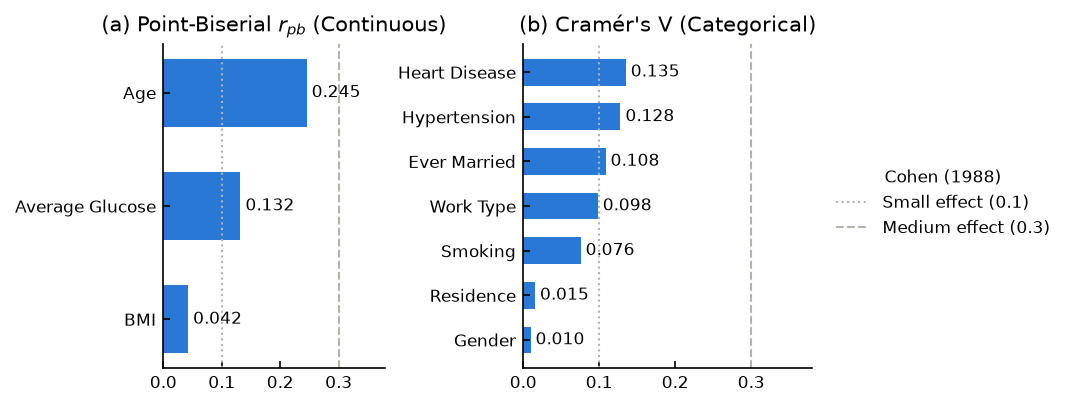

In [16]:
def cramers_v(x: pd.Series, y: pd.Series) -> float:
    """Return Cramér's V, the strength of association between two categorical variables (0 to 1)."""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))))


point_biserial = data[continuous].corrwith(data["stroke"]).sort_values().rename(display_label)
cramer = pd.Series({display_label(c): cramers_v(data[c], data["stroke"]) for c in categorical}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.6), width_ratios=[1, 1.3])
panels = [
    (axes[0], point_biserial, "Point-Biserial $r_{pb}$ (Continuous)"),
    (axes[1], cramer, "Cramér's V (Categorical)"),
]
for ax, values, title in panels:
    bars = ax.barh(values.index, values.to_numpy(), height=0.6)
    ax.bar_label(bars, fmt=" %.3f", fontsize=8)
    for x, style in [(0.1, ":"), (0.3, "--")]:
        ax.axvline(x, color=COLORS["grey"], ls=style, lw=1)
    ax.set_xlim(0, 0.38)
    ax.set_title(title)
label_panels(axes)
fig.legend(
    handles=[
        Line2D([], [], color=COLORS["grey"], ls=":", lw=1, label="Small effect (0.1)"),
        Line2D([], [], color=COLORS["grey"], ls="--", lw=1, label="Medium effect (0.3)"),
    ],
    title="Cohen (1988)",
    loc="outside right center",
)
save_figure(fig, "eda_association")
plt.show()

<a id="sec-interactions"></a>
## 7. Feature interactions

Age dominates [Section 6](#sec-bivariate), which raises two questions:
1. Are the other associations explained by age?
2. Which features move together? This matters for SHAP (Lundberg & Lee, 2017): when features are correlated, the model can rely on either one, and the SHAP values (feature attributions) may be shared between them. Each can then look more or less important than its own effect (Aas et al., 2021).

### 7.1 Continuous features against each other

Every pair of continuous features, coloured by outcome.

**Result:**
- Strokes sit almost entirely above about 40 years (8 of 249 below; see legend). Many fall in the high-glucose band.
- BMI rises with age through adulthood. Glucose and BMI barely relate.
- **Two strokes in children** (circled; rows in the table below) stand out from the rest of the stroke cloud:
  - Neither child has hypertension, heart disease or high glucose.
  - Smoking is `Unknown`, and one is missing BMI.
  - Childhood stroke occurs but is rare (Mallick et al., 2014).

These two rows are **possible label noise**. They are kept, but a model is unlikely to learn anything meaningful from them.

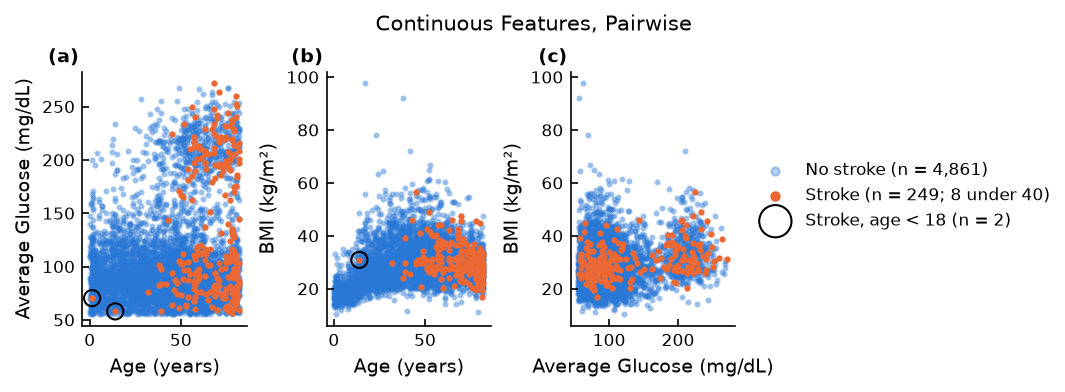

In [17]:
pairs = [("age", "avg_glucose_level"), ("age", "bmi"), ("avg_glucose_level", "bmi")]
no_stroke, strokes = data[data["stroke"] == 0], data[data["stroke"] == 1]
child_strokes = strokes[strokes["age"] < 18]

fig, axes = plt.subplots(1, 3, figsize=(FIGURE_WIDTH, 2.5))
for ax, (x, y) in zip(axes, pairs, strict=True):
    ax.scatter(no_stroke[x], no_stroke[y], s=4, alpha=0.35, label=f"No stroke (n = {len(no_stroke):,})")
    ax.scatter(
        strokes[x],
        strokes[y],
        s=4,
        color=COLORS["orange"],
        label=f"Stroke (n = {len(strokes)}; {(strokes['age'] < 40).sum()} under 40)",
    )
    if x == "age":
        ax.scatter(
            child_strokes[x],
            child_strokes[y],
            s=60,
            facecolors="none",
            edgecolors="black",
            label=f"Stroke, age < 18 (n = {len(child_strokes)})",
        )
    ax.set(xlabel=axis_label(x), ylabel=axis_label(y))
label_panels(axes)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center", markerscale=2)
fig.suptitle("Continuous Features, Pairwise")
save_figure(fig, "eda_scatter")
plt.show()

In [18]:
child_strokes

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
162,69768,Female,1.32,0,0,No,Children,Urban,70.37,NaN,Unknown,1
245,49669,Female,14.00,0,0,No,Children,Rural,57.93,30.9,Unknown,1


<a id="sec-confounding"></a>
### 7.2 Confounding by age

A confounder is a variable associated with both a feature and the outcome, which creates an apparent link between them (Rothman et al., 2008). Here, age differs across marital status and work type, and stroke rises with age.

**Result:**
- Ever-married patients have a median age of 54 vs 18 for never-married; self-employed 63 vs 6 for children.
- Their higher crude stroke rates ([Section 6.2](#sec-6-2)) therefore largely reflect age, not marriage or work.
- A model may still use these features as stand-ins for age.

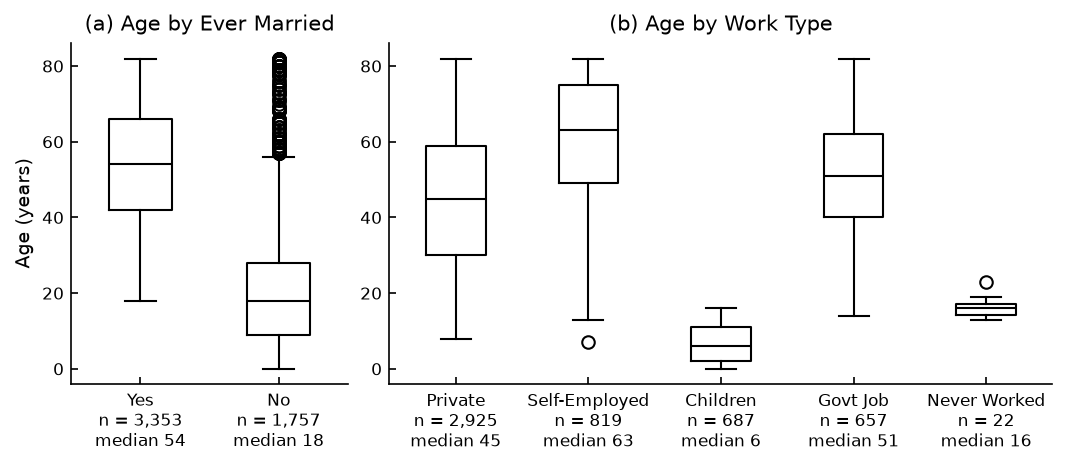

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 3), width_ratios=[1, 2.4])
for ax, column in zip(axes, ["ever_married", "work_type"], strict=True):
    levels = data[column].value_counts().index
    groups = [data.loc[data[column] == level, "age"] for level in levels]
    ax.boxplot(
        groups,
        widths=0.45,
        tick_labels=[
            f"{level}\nn = {len(g):,}\nmedian {g.median():.0f}"
            for level, g in zip(levels, groups, strict=True)
        ],
    )
    ax.set_title(f"Age by {display_label(column)}")
axes[0].set_ylabel("Age (years)")
label_panels(axes)
save_figure(fig, "eda_age_by_group")
plt.show()

<a id="sec-7-3"></a>

### 7.3 Stratified analysis: conditions within age bands

Comparing stroke rates with and without each condition *inside* each age band holds age roughly constant (stratification). Bars are labelled with the rate and strokes / patients; the factor above each pair is the rate ratio (with ÷ without).

**Result:**
- From 40 upward, patients with each condition have a 1.3–2.1× higher stroke rate.
- Unlike marriage, the associations of hypertension and heart disease with stroke therefore persist **within age bands** (an observed association, not proof of causation).
- Under 40 there are too few strokes to judge.

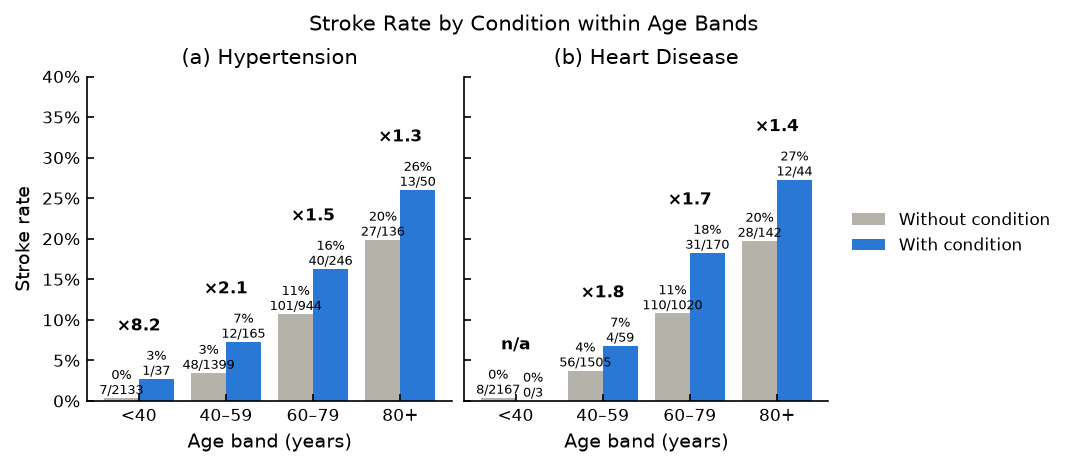

In [20]:
age_band = pd.cut(data["age"], [0, 40, 60, 80, np.inf], right=False, labels=["<40", "40–59", "60–79", "80+"])
x = np.arange(len(age_band.cat.categories))

fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 3), sharey=True)
for ax, column in zip(axes, ["hypertension", "heart_disease"], strict=True):
    rates = data.groupby([age_band, data[column]], observed=True)["stroke"].agg(
        rate="mean", strokes="sum", n="size"
    )
    without, with_condition = rates.xs(0, level=column), rates.xs(1, level=column)
    for k, (subset, color, label) in enumerate(
        [(without, COLORS["grey"], "Without condition"), (with_condition, COLORS["blue"], "With condition")]
    ):
        bars = ax.bar(x + (k - 0.5) * 0.4, subset["rate"], width=0.4, color=color, label=label)
        ax.bar_label(
            bars, labels=[f"{s.rate:.0%}\n{s.strokes}/{s.n}" for s in subset.itertuples()], fontsize=6
        )
    for i, (a, b) in enumerate(zip(without["rate"], with_condition["rate"], strict=True)):
        ax.text(
            i,
            max(a, b) + 0.06,
            f"×{b / a:.1f}" if a and b else "n/a",
            ha="center",
            fontsize=8,
            fontweight="bold",
        )
    ax.set_xticks(x, age_band.cat.categories)
    ax.set(xlabel="Age band (years)", title=display_label(column))
axes[0].set_ylabel("Stroke rate")
label_panels(axes)
axes[0].set_ylim(0, 0.4)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right center")
fig.suptitle("Stroke Rate by Condition within Age Bands")
save_figure(fig, "eda_risk_by_age")
plt.show()

<a id="sec-7-4"></a>

### 7.4 Feature–feature correlation

Spearman's rank correlation $\rho$ (Spearman, 1904) measures monotonic association and is robust to the skewed and bimodal distributions in [Section 5](#sec-univariate).

**Which features are included:**
- Only variables with a meaningful order can be ranked: the three continuous features, plus the binary features coded 0/1.
  - `hypertension` and `heart_disease` are already 0/1.
  - `ever_married` Yes = 1, `Residence_type` Urban = 1, `gender` Male = 1 (the single `Other` patient is excluded).
- Multi-category features (`work_type`, `smoking_status`) have no order, so they are excluded; their link to age is shown in Sections [4.2](#sec-4-2) and [7.2](#sec-confounding).
- Rows with missing BMI are excluded pairwise.

**Result:**
- The only strong pair is **age and ever_married** (ρ = 0.66).
- BMI is moderately linked to age and marriage (about 0.4); everything else is weak.
- If SHAP gives `ever_married` noticeable importance, it is likely sharing attribution with age.

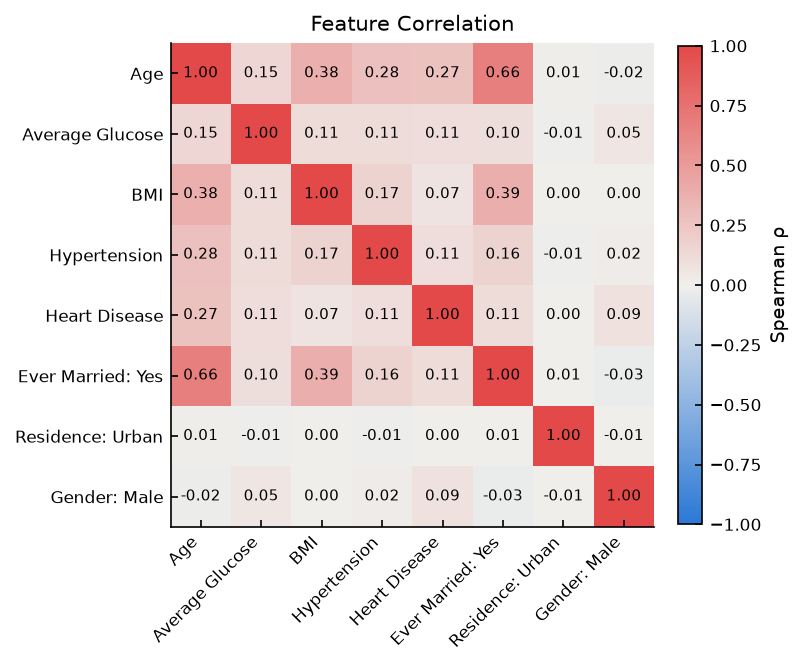

In [21]:
binary = data[data["gender"] != "Other"]
encoded = binary[[*continuous, "hypertension", "heart_disease"]].assign(
    ever_married=(binary["ever_married"] == "Yes").astype(int),
    residence_urban=(binary["Residence_type"] == "Urban").astype(int),
    gender_male=(binary["gender"] == "Male").astype(int),
)
names = {
    "ever_married": "Ever Married: Yes",
    "residence_urban": "Residence: Urban",
    "gender_male": "Gender: Male",
}
corr = encoded.corr(method="spearman").rename(index=lambda c: names.get(c, display_label(c)))
corr.columns = corr.index
diverging = LinearSegmentedColormap.from_list("diverging", [COLORS["blue"], "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH * 0.75, 4.6))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Feature Correlation")
save_figure(fig, "eda_correlation")
plt.show()

<a id="sec-takeaways"></a>
## 8. Key takeaways

1. **Severe imbalance** ([Section 3](#sec-target)):
   - About 20 : 1 (4.9% stroke), so accuracy is misleading.
   - Training is oversampled and evaluation should use recall.
2. **Age dominates** ([Section 6](#sec-bivariate)):
   - The stroke rate rises from 0.2% (<18) to 21.5% (80+).
   - Age has the largest association with stroke ($r_{pb}$ = 0.245).
3. **Associations not explained by age** ([Section 7.3](#sec-7-3)):
   - Hypertension and heart disease are associated with a 1.3–2.1× higher stroke rate within the same age band.
   - Stroke patients fall in the high-glucose peak more often than non-stroke patients ([Section 6.1](#sec-6-1)).
4. **Proxies for age** ([Section 7.2](#sec-confounding)):
   - `ever_married` (ρ = 0.66 with age), self-employment and former smoking show higher stroke rates largely because those patients are older.
   - Expect SHAP to share attribution between them and age.
5. **Data issues the model can exploit** ([Section 4](#sec-quality)):
   - Missing BMI carries 4.7× the stroke share and is filled with 0, so BMI = 0 may act as a stroke flag.
   - `smoking_status = Unknown` (30%) is concentrated in children.
   - Two child strokes may be label noise.
6. **Weak signal overall** ([Section 6.3](#sec-6-3)):
   - Every association is small by Cohen's (1988) guideline.
   - BMI, gender and residence carry almost none.

<a id="sec-references"></a>
## 9. References

Aas, K., Jullum, M., & Løland, A. (2021). Explaining individual predictions when features are dependent: More accurate approximations to Shapley values. *Artificial Intelligence, 298*, 103502. https://doi.org/10.1016/j.artint.2021.103502

American Diabetes Association. (2021). 2. Classification and diagnosis of diabetes: *Standards of Medical Care in Diabetes—2021*. *Diabetes Care, 44*(Suppl. 1), S15–S33. https://doi.org/10.2337/dc21-S002

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates.

Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

deepfindr. (2021). *xai-series* [Computer software]. GitHub. https://github.com/deepfindr/xai-series

fedesoriano. (2021). *Stroke prediction dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*, 4765–4774.

Mallick, A. A., Ganesan, V., Kirkham, F. J., Fallon, P., Hedderly, T., McShane, T., Parker, A. P., Wassmer, E., Wraige, E., Amin, S., Edwards, H. B., Tilling, K., & O'Callaghan, F. J. K. (2014). Childhood arterial ischaemic stroke incidence, presenting features, and risk factors: A prospective population-based study. *The Lancet Neurology, 13*(1), 35–43. https://doi.org/10.1016/S1474-4422(13)70290-4

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491

Pearson, K. (1900). On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science, 50*(302), 157–175. https://doi.org/10.1080/14786440009463897

Rothman, K. J., Greenland, S., & Lash, T. L. (2008). *Modern epidemiology* (3rd ed.). Lippincott Williams & Wilkins.

Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101. https://doi.org/10.2307/1412159

Tate, R. F. (1954). Correlation between a discrete and a continuous variable: Point-biserial correlation. *The Annals of Mathematical Statistics, 25*(3), 603–607. https://doi.org/10.1214/aoms/1177728730

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.